In [2]:
import pandas as pd
import numpy as np

df = pd.read_excel(r"C:\Users\shakthi vasan\Desktop\ml project\India_Environmental_Disaster_Analytics_All_Data_2015_2025_5500.xlsx")

df.head()

,RecordID,Date,Year,MonthNumber,Month,Season,State,Region,DisasterType,EventCount,...,DisplacedPopulation,EconomicLoss_CroreINR,PropertyDamage_CroreINR,AgriculturalLoss_CroreINR,InfrastructureDamage_CroreINR,Severity,RiskScore,Latitude,Longitude,RiskLevel
0,IND-DIS-03333,2015-01-01,2015,1,January,Winter,Himachal Pradesh,North,Heatwave,2,...,1219,76.35,33.67,20.44,22.24,High,53,9.4408,85.1923,High
1,IND-DIS-03378,2015-01-02,2015,1,January,Winter,Madhya Pradesh,Central,Drought,1,...,89,16.08,10.52,2.27,3.29,Moderate,42,16.7316,80.5376,Moderate
2,IND-DIS-03880,2015-01-03,2015,1,January,Winter,Ladakh,North,Drought,1,...,40,5.45,3.53,0.81,1.11,Moderate,49,29.8970,81.0547,Moderate
3,IND-DIS-02531,2015-01-03,2015,1,January,Winter,Madhya Pradesh,Central,Wildfire,3,...,415,32.99,6.19,7.35,19.45,High,54,34.5920,81.3419,High
4,IND-DIS-01190,2015-01-03,2015,1,January,Winter,Meghalaya,Northeast,Storm,1,...,252,19.06,11.96,5.81,1.29,High,77,34.7166,71.8721,Very High


In [3]:
print(df.columns.tolist())

['RecordID', 'Date', 'Year', 'MonthNumber', 'Month', 'Season', 'State', 'Region', 'DisasterType', 'EventCount', 'Rainfall_mm', 'AvgTemperature_C', 'AffectedPopulation', 'Deaths', 'Injured', 'DisplacedPopulation', 'EconomicLoss_CroreINR', 'PropertyDamage_CroreINR', 'AgriculturalLoss_CroreINR', 'InfrastructureDamage_CroreINR', 'Severity', 'RiskScore', 'Latitude', 'Longitude', 'RiskLevel']


In [5]:


target = "RiskLevel"  
print(df[target].value_counts())

RiskLevel
High         2609
Very High    1786
Moderate     1002
Low           103
Name: count, dtype: int64


In [9]:
categorical_cols = df.select_dtypes(include=['object']).columns

numerical_cols = df.select_dtypes(include=np.number).columns

print("Categorical Columns:", categorical_cols.tolist())

print("Numerical Columns:", numerical_cols.tolist())

Categorical Columns: ['RecordID', 'Month', 'Season', 'State', 'Region', 'DisasterType', 'Severity', 'RiskLevel']
Numerical Columns: ['Year', 'MonthNumber', 'EventCount', 'Rainfall_mm', 'AvgTemperature_C', 'AffectedPopulation', 'Deaths', 'Injured', 'DisplacedPopulation', 'EconomicLoss_CroreINR', 'PropertyDamage_CroreINR', 'AgriculturalLoss_CroreINR', 'InfrastructureDamage_CroreINR', 'RiskScore', 'Latitude', 'Longitude']


In [11]:
# target column
target = "RiskLevel"

# features: all columns except the target
X = df.drop(columns=[target])

# keep only non-target categorical columns
categorical_cols = [col for col in df.select_dtypes(include=['object']).columns if col != target]

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

# target
y = df[target]

In [12]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

# Encode the target labels
y = le.fit_transform(y)

print("Risk Categories:", le.classes_)

Risk Categories: ['High' 'Low' 'Moderate' 'Very High']


In [13]:
print("Input Shape:", X.shape)

print("Target Shape:", y.shape)

print(X.head())

Input Shape: (5500, 5579)
Target Shape: (5500,)
        Date  Year  MonthNumber  EventCount  Rainfall_mm  AvgTemperature_C  \
0 2015-01-01  2015            1           2         21.3              20.6   
1 2015-01-02  2015            1           1         19.4              17.4   
2 2015-01-03  2015            1           1          2.4              15.9   
3 2015-01-03  2015            1           3         46.0              20.4   
4 2015-01-03  2015            1           1         19.3              18.8   

   AffectedPopulation  Deaths  Injured  DisplacedPopulation  ...  \
0                2029       1        6                 1219  ...   
1                 473       0        0                   89  ...   
2                 806       1        0                   40  ...   
3                2234       0        2                  415  ...   
4                 648       0        0                  252  ...   

   DisasterType_Drought  DisasterType_Earthquake  DisasterType_Flood  \
0 

In [7]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Recreate X if it was not defined in the current notebook session
if 'X' not in globals():
    target = "RiskLevel"
    if 'df' not in globals():
        # Read the dataset only if it doesn't already exist in the notebook session
        if 'pd' not in globals():
            df = pd.read_excel(r"C:\Users\shakthi vasan\Desktop\ml project\India_Environmental_Disaster_Analytics_All_Data_2015_2025_5500.xlsx")
    if 'df' not in globals():
        df = pd.read_excel(r"C:\Users\shakthi vasan\Desktop\ml project\India_Environmental_Disaster_Analytics_All_Data_2015_2025_5500.xlsx")

    X = df.drop(columns=[target])

    categorical_cols = [col for col in df.select_dtypes(include=['object']).columns if col != target]
    X = pd.get_dummies(
        X,
        columns=categorical_cols,
        drop_first=True,
        dtype=int
    )

X.to_csv("Disaster_ML_Features.csv", index=False)

# Ensure target labels are encoded before exporting
if 'le' not in globals():
    le = LabelEncoder()

if 'y' not in globals():
    y = df[target].copy()

# Fit encoder only if y is still in original string form
if not isinstance(y, (list, tuple, pd.Series)) or not pd.api.types.is_integer_dtype(pd.Series(y)):
    y = le.fit_transform(y)

pd.DataFrame({
    "Risk_Band": le.inverse_transform(y)
}).to_csv("Disaster_ML_Target.csv", index=False)

# train_test_split

In [8]:
from sklearn.model_selection import train_test_split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [10]:
print("X Train:", X_train.shape)
print("X Test:", X_test.shape)

print("Y Train:", y_train.shape)
print("Y Test:", y_test.shape)

X Train: (4400, 5579)
X Test: (1100, 5579)
Y Train: (4400,)
Y Test: (1100,)


In [12]:
import pandas as pd

print("Training Distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting Distribution:")
print(pd.Series(y_test).value_counts())

Training Distribution:
0    2087
3    1429
2     802
1      82
Name: count, dtype: int64

Testing Distribution:
0    522
3    357
2    200
1     21
Name: count, dtype: int64


In [13]:
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)

pd.DataFrame(y_train).to_csv("y_train.csv", index=False)
pd.DataFrame(y_test).to_csv("y_test.csv", index=False)

print("Training and Testing Data Saved Successfully!")

Training and Testing Data Saved Successfully!


# Model Training

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

In [15]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),
    
    "KNN": KNeighborsClassifier(n_neighbors=5),
    
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [17]:
trained_models = {}

for name, model in models.items():
    
    # Remove the datetime column so all model inputs are numeric
    X_train = X_train.drop(columns=["Date"], errors="ignore")
    X_test = X_test.drop(columns=["Date"], errors="ignore")

    trained_models = {}

    for name, model in models.items():
        model.fit(X_train, y_train)
        trained_models[name] = model
        print(name, "Training Completed")
    
    trained_models[name] = model
    
    print(name, "Training Completed")

c:\Users\shakthi vasan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Training Completed
Decision Tree Training Completed
Random Forest Training Completed
KNN Training Completed
Gradient Boosting Training Completed
Gradient Boosting Training Completed


c:\Users\shakthi vasan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Training Completed
Decision Tree Training Completed
Random Forest Training Completed
KNN Training Completed
Gradient Boosting Training Completed
Gradient Boosting Training Completed


c:\Users\shakthi vasan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Training Completed
Decision Tree Training Completed
Random Forest Training Completed
KNN Training Completed
Gradient Boosting Training Completed
Gradient Boosting Training Completed


c:\Users\shakthi vasan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Training Completed
Decision Tree Training Completed
Random Forest Training Completed
KNN Training Completed
Gradient Boosting Training Completed
Gradient Boosting Training Completed


c:\Users\shakthi vasan\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Training Completed
Decision Tree Training Completed
Random Forest Training Completed
KNN Training Completed
Gradient Boosting Training Completed
Gradient Boosting Training Completed


In [18]:
for name, model in trained_models.items():
    
    train_accuracy = model.score(X_train, y_train)
    
    print(name, ":", round(train_accuracy * 100, 2), "%")

Logistic Regression : 99.89 %
Decision Tree : 100.0 %
Random Forest : 100.0 %
KNN : 64.93 %
Gradient Boosting : 100.0 %


In [19]:
import joblib

for name, model in trained_models.items():
    
    filename = name.replace(" ", "_") + ".pkl"
    
    joblib.dump(model, filename)
    
    print(filename, "Saved Successfully")

Logistic_Regression.pkl Saved Successfully
Decision_Tree.pkl Saved Successfully
Random_Forest.pkl Saved Successfully
KNN.pkl Saved Successfully
Gradient_Boosting.pkl Saved Successfully


# Model Evaluation

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average='weighted', zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average='weighted', zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average='weighted', zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": round(accuracy * 100, 2),
        "Precision": round(precision * 100, 2),
        "Recall": round(recall * 100, 2),
        "F1 Score": round(f1 * 100, 2)
    })

results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     99.82      99.82   99.82     99.82
1        Decision Tree    100.00     100.00  100.00    100.00
2        Random Forest     85.09      85.09   85.09     82.88
3                  KNN     46.45      43.23   46.45     43.20
4    Gradient Boosting    100.00     100.00  100.00    100.00


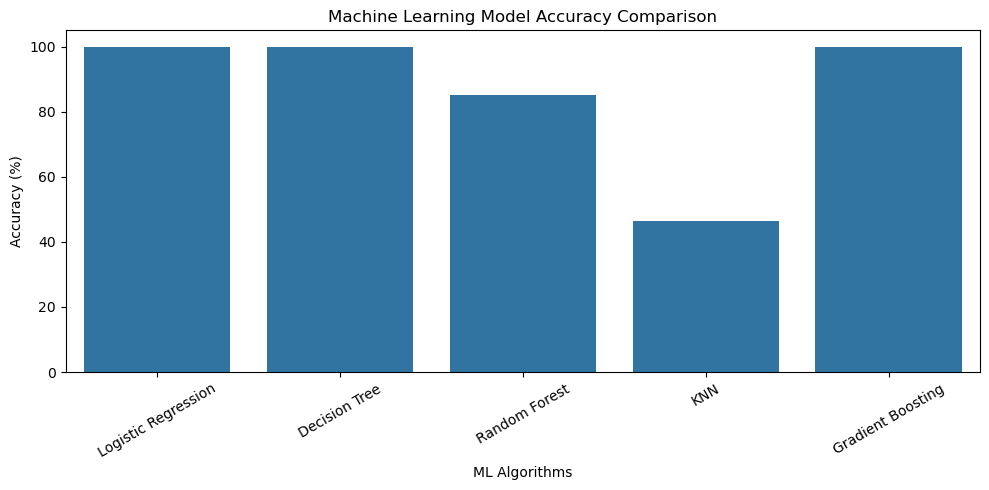

In [22]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("ML Algorithms")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [23]:
best_model_name = results_df.loc[
    results_df["Accuracy"].idxmax(), "Model"
]

print("Best Performing Model:", best_model_name)

Best Performing Model: Decision Tree


In [24]:
best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       522
           1       1.00      1.00      1.00        21
           2       1.00      1.00      1.00       200
           3       1.00      1.00      1.00       357

    accuracy                           1.00      1100
   macro avg       1.00      1.00      1.00      1100
weighted avg       1.00      1.00      1.00      1100



# confusion matrix

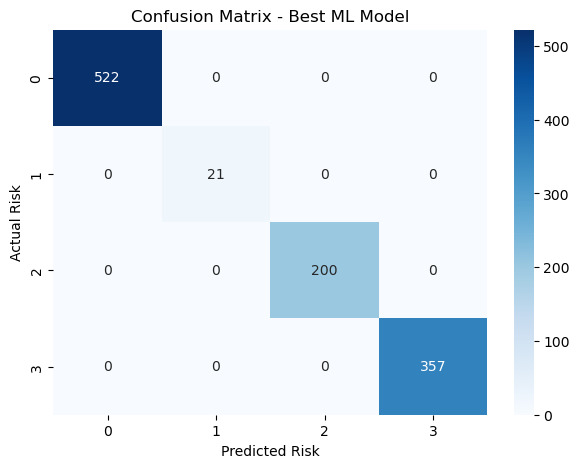

In [25]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - Best ML Model")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")

plt.show()

In [26]:
results_df.to_csv(
    "ML_Model_Comparison.csv",
    index=False
)

print("Model Evaluation Results Saved!")

Model Evaluation Results Saved!


In [27]:
best_model_name = results_df.loc[
    results_df["Accuracy"].idxmax(), "Model"
]

best_model = trained_models[best_model_name]

print("Selected Model:", best_model_name)

Selected Model: Decision Tree


In [28]:
def predict_disaster_risk(input_data):

    input_df = pd.DataFrame([input_data])

    input_df = pd.get_dummies(input_df)

    input_df = input_df.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    prediction = best_model.predict(input_df)

    risk = le.inverse_transform(prediction)

    return risk[0]

In [29]:
sample_data = {
    "Rainfall_mm": 250,
    "Temperature_C": 32,
    "Humidity_pct": 90,
    "Wind_Speed_kmh": 45
}

prediction = predict_disaster_risk(sample_data)

print("Predicted Disaster Risk:", prediction)

Predicted Disaster Risk: Low


In [30]:
if prediction == "Low":
    print("LOW RISK - Green")

elif prediction == "Moderate":
    print("MODERATE RISK - Yellow")

elif prediction == "High":
    print("HIGH RISK - Orange")

elif prediction == "Severe":
    print("SEVERE RISK - Red")

else:
    print("Predicted Category:", prediction)

LOW RISK - Green


In [31]:
import joblib

joblib.dump(best_model, "Best_Disaster_Prediction_Model.pkl")

joblib.dump(le, "Risk_Label_Encoder.pkl")

print("Best Model Saved Successfully!")

Best Model Saved Successfully!
